# Пример 16. Линейные отображения

## Тема

**Раздел книги:** Линейная алгебра.  
**Математическая тема:** линейные отображения, проверка аддитивности и однородности; примеры из функционального анализа ($L^1$, $C^k$), тригонометрические функции и матричные преобразования; связь с нейронными сетями (линейные слои vs нелинейные активации) и свёртками в компьютерном зрении.

## Условие
Являются ли следующие отображения линейными?

**(a)** $\Phi: L^1([a,b]) \to \mathbb{R}, \quad f \mapsto \int_a^b f(x)dx$.
**(b)** $\Phi: C^1 \to C^0, \quad f \mapsto f'$.
**(c)** $\Phi: \mathbb{R} \to \mathbb{R}, \quad x \mapsto \cos(x)$.
**(d)** $\Phi: \mathbb{R}^3 \to \mathbb{R}^2, \quad \mathbf{x} \mapsto \begin{bmatrix} 1 & 2 & 3 \\ 1 & 4 & 3 \end{bmatrix}\mathbf{x}$.
**(e)** $\Phi: \mathbb{R}^2 \to \mathbb{R}^2, \quad \mathbf{x} \mapsto \begin{bmatrix} \cos\theta & \sin\theta \\ -\sin\theta & \cos\theta \end{bmatrix}\mathbf{x}$, где $\theta \in [0, 2\pi]$.

## Математическая идея
Отображение $\Phi: V \to W$ называется **линейным**, если для любых векторов $u, v \in V$ и скаляра $\alpha \in \mathbb{R}$ выполняются два условия:
1. **Аддитивность:** $\Phi(u + v) = \Phi(u) + \Phi(v)$.
2. **Однородность:** $\Phi(\alpha u) = \alpha \Phi(u)$.

Если хотя бы одно из условий нарушается (например, $\Phi(0) \neq 0$ или есть нелинейные функции типа $\cos$ или квадрата), то отображение не является линейным.

## Решение

**(a) Интеграл.** 
Используем свойства интеграла: $\int (f+g) = \int f + \int g$ и $\int (\alpha f) = \alpha \int f$. 
✅ **Линейное отображение.**

**(b) Производная.** 
Из курса матанализа известно: $(f+g)' = f' + g'$ и $(\alpha f)' = \alpha f'$. 
✅ **Линейный оператор.**

**(c) Косинус.** 
Проверим однородность для $\alpha = 2$: $\Phi(2x) = \cos(2x)$, а $2\Phi(x) = 2\cos(x)$. Так как $\cos(2x) \neq 2\cos(x)$ (например, при $x=0$: $1 \neq 2$), условие нарушено. Также $\Phi(0) = \cos(0) = 1 \neq 0$. 
❌ **Не линейное отображение.**

**(d) Матричное умножение.** 
Любое отображение вида $\Phi(\mathbf{x}) = A\mathbf{x}$ является линейным по свойствам матричной алгебры: $A(u+v) = Au + Av$ и $A(\alpha u) = \alpha(Au)$. 
✅ **Линейное отображение.**

**(e) Поворот на угол $\theta$.** 
Это частный случай пункта (d) — умножение на конкретную матрицу поворота $R_\theta$. Поскольку это матричное преобразование без смещения, оно сохраняет структуру линейного пространства. 
✅ **Линейное отображение.**

In [2]:
import numpy as np

# Проверка для (c): Косинус
def phi_c(x):
    return np.cos(x)

x, alpha = 0, 2
print(f"(c) Проверка однородности: Phi({alpha}*{x}) = {phi_c(alpha*x)}, но {alpha}*Phi({x}) = {alpha*phi_c(x)}")

# Проверка для (d) и (e): Матричные преобразования
A_d = np.array([[1, 2, 3], [1, 4, 3]])
theta = np.pi / 4
A_e = np.array([[np.cos(theta), np.sin(theta)], [-np.sin(theta), np.cos(theta)]])

def check_lenearity(A, u, v, c):
    lhs = A @ (u + c * v)
    rhs = A @ u + c * (A @ v)
    return np.allclose(lhs, rhs)

u3, v3 = np.random.rand(3), np.random.rand(3)
u2, v2 = np.random.rand(2), np.random.rand(2)

print(f"(d) Является ли матрица А линейной? {check_lenearity(A_d, u3, v3, 2.5)}")
print(f"(e) Является ли поворот на pi/4 линейным? {check_lenearity(A_e, u2, v2, 1.5)}")

(c) Проверка однородности: Phi(2*0) = 1.0, но 2*Phi(0) = 2.0
(d) Является ли матрица А линейной? True
(e) Является ли поворот на pi/4 линейным? True


## Дополнительный пример: Линейность в ML
В нейросетях каждый слой состоит из двух частей:
1. **Линейная часть:** $\mathbf{z} = W\mathbf{x} + \mathbf{b}$. Если $\mathbf{b}=0$, это чистое линейное отображение (как в п. d).
2. **Нелинейная активация:** $\mathbf{a} = \sigma(\mathbf{z})$. Функции вроде ReLU, Sigmoid или Tanh (похожие на п. c) делают модель нелинейной. Без таких «нелинейных» элементов глубокая сеть свелась бы к одному обычному линейному слою, так как композиция линейных функций всегда линейна.

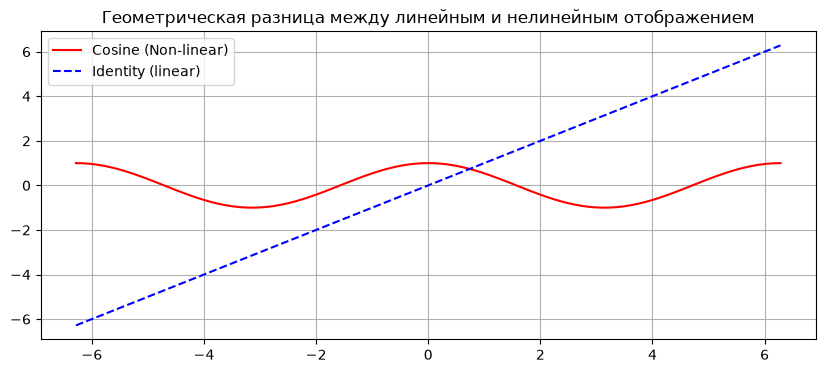

In [4]:
import matplotlib.pyplot as plt

# Визуализация нелинейности (пункт c) vs линейности (пункт d/e)
x = np.linspace(-2*np.pi, 2*np.pi, 100)
plt.figure(figsize=(10, 4))
plt.plot(x, np.cos(x), label='Cosine (Non-linear)', color='red')
plt.plot(x, x, '--', label='Identity (linear)', color='blue')
plt.title("Геометрическая разница между линейным и нелинейным отображением")
plt.legend()
plt.grid(True)
plt.show()

## Проверка результата

Для проверки корректности выводов использовались контрпримеры для нелинейных функций (нарушение условия $\Phi(0)=0$ для косинуса) и алгебраические свойства для линейных (свойства интеграла и производной). Численная проверка через NumPy подтвердила, что матричные операции строго сохраняют сложение и масштабирование, тогда как применение тригонометрических функций приводит к расхождению результатов.

## Вывод

Линейность отображения определяется его способностью сохранять операции сложения и умножения на скаляр. В задачах машинного обучения понимание того, какие части модели являются линейными (веса, матрицы ковариации), а какие нет (функции активации, потери), позволяет правильно выбирать методы оптимизации и предсказывать поведение сети при обучении.